# 1. Missing Values

In [8]:
import pathlib, zipfile
import numpy as np, pandas as pd
from scipy.stats import boxcox
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer

# Locate heart.csv whether this runs in Colab or in a local clone of the repo.
def find_heart_csv():
    roots = [pathlib.Path.cwd(), pathlib.Path("/content"),
             pathlib.Path("/content/ECS171-Project")]
    for r in roots:
        for p in (r / "heart.csv", r / "data" / "heart.csv"):
            if p.exists():
                return p
    for r in roots:                      # not unpacked yet -> extract the repo zip
        z = r / "heartfailure_dataset.zip"
        if z.exists():
            zipfile.ZipFile(z).extractall(r / "data")
            return r / "data" / "heart.csv"
    raise FileNotFoundError("heart.csv not found - upload it or clone the repo")

CSV = find_heart_csv()
print("loading", CSV)
df_raw = pd.read_csv(CSV)
df = df_raw.copy()
# Flag first (a fixed rule, not learned from data, so no leakage)
df["Chol_missing"] = (df["Cholesterol"] == 0).astype(int)

# Zeros -> NaN (imputation happens after the split, in 5.6)
df[["Cholesterol", "RestingBP"]] = df[["Cholesterol", "RestingBP"]].replace(0, np.nan)
print(df.isnull().sum())

Age                 0
Sex                 0
ChestPainType       0
RestingBP           1
Cholesterol       172
FastingBS           0
RestingECG          0
MaxHR               0
ExerciseAngina      0
Oldpeak             0
ST_Slope            0
HeartDisease        0
Chol_missing        0
dtype: int64


# 2. Outliers

In [9]:
continuous_features = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

Q1 = df[continuous_features].quantile(0.25)
Q3 = df[continuous_features].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df[continuous_features] < Q1 - 1.5*IQR) |
            (df[continuous_features] > Q3 + 1.5*IQR)).sum()
print(outliers)   # keep them; we'll reduce their impact with transforms

Age             0
RestingBP      27
Cholesterol    23
MaxHR           2
Oldpeak        16
dtype: int64


# 3. Categorical Features Encoding

In [10]:
# Binary / ordinal -> integers (notebook: no one-hot needed)
df["Sex"] = df["Sex"].map({"F": 0, "M": 1})
df["ExerciseAngina"] = df["ExerciseAngina"].map({"N": 0, "Y": 1})
df["ST_Slope"] = df["ST_Slope"].map({"Down": 0, "Flat": 1, "Up": 2})  # ordinal, as the notebook treats slope
# FastingBS is already 0/1

# Nominal -> one-hot (notebook: cp and restecg)
df_encoded = pd.get_dummies(df, columns=["ChestPainType", "RestingECG"], drop_first=True)
bool_cols = df_encoded.select_dtypes("bool").columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

In [ ]:
# --- what the encoding actually did -------------------------------------
# ChestPainType  TA  = Typical Angina       ATA = Atypical Angina
#                NAP = Non-Anginal Pain     ASY = Asymptomatic
# RestingECG     Normal = no resting abnormality
#                ST     = ST-T wave abnormality (T-wave inversion and/or
#                         ST elevation or depression > 0.05 mV)
#                LVH    = left ventricular hypertrophy (Estes' criteria)
# ST_Slope       Up = upsloping (normal response); Flat / Down = abnormal

cat_cols = ["Sex", "ExerciseAngina", "ST_Slope", "ChestPainType", "RestingECG"]

print(f"shape: {df_raw.shape} -> {df_encoded.shape}")
print("added  :", [c for c in df_encoded.columns if c not in df_raw.columns])
print("removed:", [c for c in df_raw.columns if c not in df_encoded.columns])


def collapse(enc, prefix, raw_levels):
    """Show a one-hot group as its dummy vector plus the level it stands for.

    drop_first=True leaves one level with no column of its own. That level is
    the reference and appears as an all-zero vector.
    """
    cols = [c for c in enc.columns if c.startswith(prefix + "_")]
    kept = [c.split("_", 1)[1] for c in cols]
    ref = (set(raw_levels) - set(kept)).pop()
    bits = enc[cols].astype(int)
    level = bits.idxmax(axis=1).str.split("_", n=1).str[1]
    level = level.where(bits.sum(axis=1) == 1, ref + " (ref)")
    return "[" + bits.astype(str).agg(",".join, axis=1) + "] " + level


# Same five column names on both sides, so the frames line up row for row.
df_before = df_raw[cat_cols].head(10)
df_after = pd.DataFrame({
    "Sex":            df_encoded["Sex"],
    "ExerciseAngina": df_encoded["ExerciseAngina"],
    "ST_Slope":       df_encoded["ST_Slope"],
    "ChestPainType":  collapse(df_encoded, "ChestPainType", df_raw["ChestPainType"].unique()),
    "RestingECG":     collapse(df_encoded, "RestingECG", df_raw["RestingECG"].unique()),
})[cat_cols].head(10)

print("\nBEFORE - raw categorical columns")
display(df_before)

print("\nAFTER - encoded (one-hot groups shown as their dummy vector)")
display(df_after)


#4. Split, impute, then transform skewed features

In [11]:
X = df_encoded.drop("HeartDisease", axis=1)
y = df_encoded["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y   # same settings as the notebook
)

# Impute the former zeros with TRAIN medians (fit on train, apply to both)
for col in ["Cholesterol", "RestingBP"]:
    med = X_train[col].median()
    X_train[col] = X_train[col].fillna(med)
    X_test[col] = X_test[col].fillna(med)

X_train_pre = X_train.copy()

# Box-Cox: lambdas learned on train only, reused on test
lambdas = {}
for col in ["Age", "RestingBP", "Cholesterol", "MaxHR"]:
    X_train[col], lambdas[col] = boxcox(X_train[col])
    X_test[col] = boxcox(X_test[col], lmbda=lambdas[col])

# Oldpeak has negatives -> Yeo-Johnson (the notebook itself suggests this)
pt = PowerTransformer(method="yeo-johnson", standardize=False)
X_train[["Oldpeak"]] = pt.fit_transform(X_train[["Oldpeak"]])
X_test[["Oldpeak"]] = pt.transform(X_test[["Oldpeak"]])

# Plot 1: Zeroes Fixed (Cholestrol)

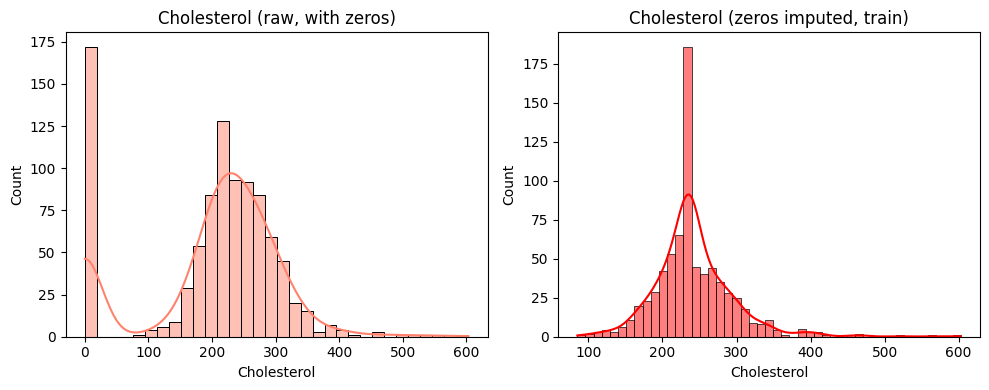

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df_raw["Cholesterol"], kde=True, ax=ax[0], color="#ff826e").set_title("Cholesterol (raw, with zeros)")
sns.histplot(X_train_pre["Cholesterol"], kde=True, ax=ax[1], color="red").set_title("Cholesterol (zeros imputed, train)")
fig.tight_layout()
plt.show()

# Plot 2: before/after transforms (after the Box-Cox/Yeo-Johnson code runs)


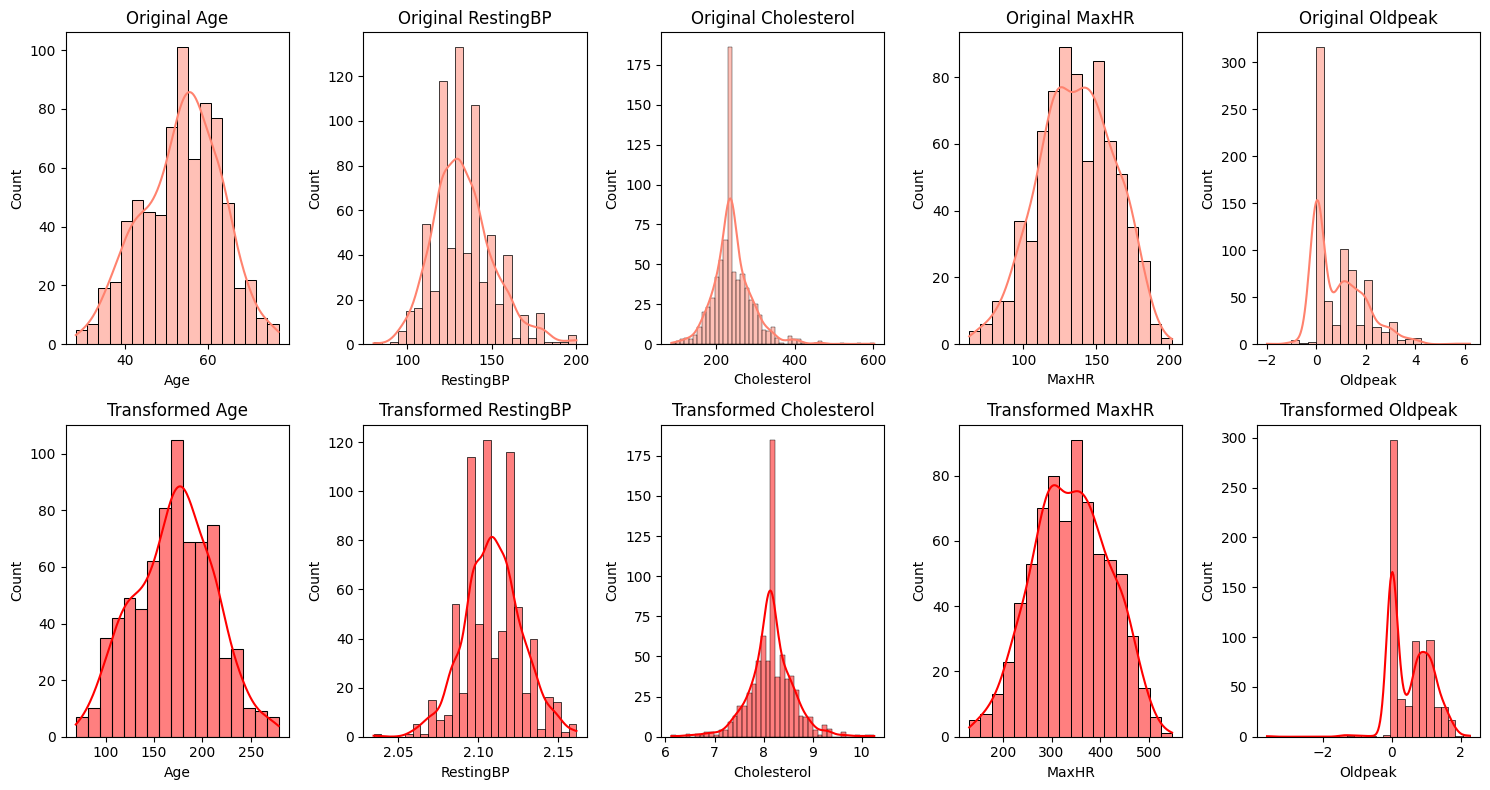

In [14]:
continuous_features = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

fig, ax = plt.subplots(2, 5, figsize=(15, 8))
for i, col in enumerate(continuous_features):
    sns.histplot(X_train_pre[col], kde=True, ax=ax[0, i], color="#ff826e").set_title(f"Original {col}")
    sns.histplot(X_train[col], kde=True, ax=ax[1, i], color="red").set_title(f"Transformed {col}")
fig.tight_layout()
plt.show()

# Downloading the cleaned dataset

In [15]:
from google.colab import files

X_train.assign(HeartDisease=y_train).to_csv("heart_train_processed.csv", index=False)
X_test.assign(HeartDisease=y_test).to_csv("heart_test_processed.csv", index=False)

files.download("heart_train_processed.csv")
files.download("heart_test_processed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>